# Background Suppression → Time to 3D   (skimage version)

**Pipeline:**
1. Read source video with OpenCV
2. Apply background subtraction **in-memory** (MOG2 or KNN) → foreground mask per frame
3. Optional Gaussian blur to reduce speckle noise
4. Stack masks → 3D volume `(T, H, W)`
5. **Reduce resolution** (area-average H×W, drop speckle blobs) → **skimage Marching Cubes** with an automatic face budget
6. Vertex colours sampled from the original frames (inside the object, at mesh resolution)
7. Plotly 3D interactive view → saved to `html/background_3d.html` (not shown inline)
8. Side-by-side **HTML page**: looping video | Plotly 3D with a time cursor → `html/background_side_by_side.html`
9. Side-by-side **combined PNG** snapshot: original frame | foreground mask | 3D matplotlib projection

**Dependencies:** `pip install scikit-image opencv-contrib-python scipy plotly numpy pandas matplotlib kaleido`


## 1 · Configuration

In [12]:
import os
import numpy as np
import cv2
import matplotlib
matplotlib.use('Agg')  # non-interactive backend — no inline display
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from skimage.measure import marching_cubes
import plotly.graph_objects as go
import time

# ── Path configuration (notebook lives in code/, outputs relative to repo root) ─
BASE_DIR   = os.path.join(os.path.dirname(os.path.abspath('__file__')), '..')
HTML_DIR   = os.path.join(BASE_DIR, 'html')
IMAGES_DIR = os.path.join(BASE_DIR, 'images') 
VIDEO_DIR = "/mnt/d/videos"
os.makedirs(HTML_DIR,   exist_ok=True)
os.makedirs(IMAGES_DIR, exist_ok=True)

# ── Input video: OpenCV sample vtest.avi ─────────────────────────────────────
# Try OpenCV's sample finder first; if not installed, download from GitHub.
import urllib.request

_VTEST_URL  = '/mnt/d/video/cars.mp4'
_VTEST_LOCAL = os.path.join(VIDEO_DIR, 'cars.mp4')

VIDEOFILE = '/mnt/d/video/cars.mp4'
 
print(f'Video      : {VIDEOFILE}')

# ── Processing parameters ────────────────────────────────────────────────────
ALGO       = 'MOG2'     # 'MOG2' or 'KNN'
MAX_FRAMES = 80         # cap to keep memory sane (set None for full video)
BLUR_K     = 5          # Gaussian blur kernel size (odd int, 0 to disable)
FLIP_H     = True       # flip horizontally (matches original notebook)
ISO_LEVEL  = 192        # Marching Cubes threshold on the foreground mask (0-255)
STEP_SIZE  = 1          # MC step size (increase to 2 for faster/coarser)

# ── Mesh-size control (keeps the Plotly HTML small) ──────────────────────────
# The mask is reduced in resolution BEFORE Marching Cubes (area-averaged, i.e.
# anti-aliased). Benchmarked against decimating the full-res mesh afterwards:
# same accuracy for the same triangle count, but 10-30x faster and no multi-GB
# 20M-face intermediate mesh.
DOWNSCALE    = 4        # initial spatial reduction factor for H and W (1 = off)
MAX_FACES    = 400_000  # face budget for the HTML (~20 MB); factor auto-increases until met
MIN_BLOB_VOX = 8        # drop connected blobs smaller than this (voxels, after downscale)

# ── Mesh colouring ───────────────────────────────────────────────────────────
COLOR_MODE   = 'video'  # 'video' = RGB sampled from the original frames, 'frame' = per-frame colourscale
COLOR_DEPTH  = 1.0      # how far inside the surface to sample, in downscaled voxels (avoids road/background pixels)

print(f'Algorithm  : {ALGO}')
print(f'Max frames : {MAX_FRAMES}')
print(f'ISO level  : {ISO_LEVEL}')
print(f'Downscale  : x{DOWNSCALE}  (face budget {MAX_FACES:,})')

Video      : /mnt/d/video/cars.mp4
Algorithm  : MOG2
Max frames : 80
ISO level  : 192
Downscale  : x4  (face budget 400,000)


## 2 · Background Subtraction (in-memory, no intermediate video)

In [13]:
# ── Create background subtractor ──────────────────────────────────────────────
if ALGO == 'MOG2':
    back_sub = cv2.createBackgroundSubtractorMOG2()
else:
    back_sub = cv2.createBackgroundSubtractorKNN()

cap = cv2.VideoCapture(VIDEOFILE)
if not cap.isOpened():
    raise RuntimeError(f'Cannot open video: {VIDEOFILE}')

fps    = cap.get(cv2.CAP_PROP_FPS)
nf_tot = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f'Video: {nf_tot} frames @ {fps:.1f} fps')

orig_frames = []   # keep one original BGR frame per step for the snapshot
mask_frames = []   # foreground masks (uint8 grayscale)
count = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # ── Foreground mask ───────────────────────────────────────────────────────
    fg_mask = back_sub.apply(frame)           # uint8, values 0/128/255

    # ── Optional blur ─────────────────────────────────────────────────────────
    if BLUR_K > 0:
        fg_mask = cv2.GaussianBlur(fg_mask, (BLUR_K, BLUR_K), 0)

    # ── Optional horizontal flip ──────────────────────────────────────────────
    if FLIP_H:
        fg_mask = cv2.flip(fg_mask, 1)
        frame   = cv2.flip(frame,   1)

    orig_frames.append(frame.copy())
    mask_frames.append(fg_mask)
    count += 1
    if MAX_FRAMES and count >= MAX_FRAMES:
        break

cap.release()

# Stack masks into 3D volume: shape = (T, H, W)
volume = np.stack(mask_frames).astype(np.float32)
print(f'Frames read    : {len(mask_frames)}')
print(f'Volume shape   : {volume.shape}  (T, H, W)')
print(f'Mask value range: {volume.min():.0f} – {volume.max():.0f}')

Video: 1501 frames @ 25.0 fps
Frames read    : 80
Volume shape   : (80, 1080, 1920)  (T, H, W)
Mask value range: 0 – 255


## 3 · Marching Cubes Iso-Surface (reduced resolution)


In [14]:
# ── Marching Cubes on a reduced-resolution volume ─────────────────────────────
# Full resolution (80 x 1080 x 1920) produced ~10 M vertices / ~20 M faces
# and an HTML file of several hundred MB. With aspectratio 1:1:1 the 1920-px
# width is squeezed into the same screen size as 80 frames, so sub-4-px
# detail is invisible anyway. Instead:
#   1. area-average each mask frame by DOWNSCALE (anti-aliased, keeps the iso level meaningful)
#   2. drop tiny speckle blobs (they cost many triangles and carry no information)
#   3. run Marching Cubes with `spacing` so coordinates stay in original pixels
#   4. if the mesh exceeds MAX_FACES, increase the factor and retry (each pass is < 1 s)
from scipy import ndimage

def reduce_volume(vol, f):
    if f <= 1:
        return vol
    h, w = vol.shape[1] // f, vol.shape[2] // f
    return np.stack([cv2.resize(fr, (w, h), interpolation=cv2.INTER_AREA) for fr in vol])

def drop_small_blobs(vol, iso, min_vox):
    if min_vox <= 1:
        return vol
    lab, _ = ndimage.label(vol >= iso)
    sizes = np.bincount(lab.ravel())
    keep = sizes >= min_vox
    keep[0] = False
    out = vol.copy()
    out[~keep[lab]] = 0
    return out

factor = max(1, int(DOWNSCALE))
t0 = time.perf_counter()
while True:
    vol_s = drop_small_blobs(reduce_volume(volume, factor), ISO_LEVEL, MIN_BLOB_VOX)
    verts, faces, normals, values = marching_cubes(
        vol_s,
        level=ISO_LEVEL,
        step_size=STEP_SIZE,
        spacing=(1.0, float(factor), float(factor)),   # (T, Y, X) back in original pixel units
        allow_degenerate=False,
    )
    print(f'  x{factor}: volume {vol_s.shape} -> {verts.shape[0]:,} vertices, {faces.shape[0]:,} faces')
    if faces.shape[0] <= MAX_FACES or factor >= 32:
        break
    factor += 2
mc_time = time.perf_counter() - t0
DOWNSCALE_USED = factor
print(f'Downscale: x{factor}   Vertices: {verts.shape[0]:,}   Faces: {faces.shape[0]:,}   time: {mc_time:.2f} s')

# Coordinate mapping: verts = (T, Y, X)  — compact dtypes for a small HTML payload
t_coord = verts[:, 0].astype(np.float32)                       # Frame # axis
x_coord = verts[:, 2].astype(np.float32)                       # Width axis (px)
y_coord = (verts[:, 1].max() - verts[:, 1]).astype(np.float32) # Height (flipped so top=top)
faces   = faces.astype(np.int32)


  x4: volume (80, 270, 480) -> 865,309 vertices, 1,749,318 faces
  x6: volume (80, 180, 320) -> 397,122 vertices, 804,109 faces
  x8: volume (80, 135, 240) -> 230,208 vertices, 466,349 faces
  x10: volume (80, 108, 192) -> 146,352 vertices, 296,821 faces
Downscale: x10   Vertices: 146,352   Faces: 296,821   time: 1.39 s


## 3b · Vertex colours from the original frames

Each vertex sits at `(t, y, x)` in original pixel units, so its colour can be read from the original frame `t` at pixel `(y, x)`.
Two refinements:
- **Sample inside the object, not on its edge.** The iso-surface lies on the mask boundary, where the pixel is half car and half road.
  We step `COLOR_DEPTH` voxels along the vertex normal in **both** directions, read the downscaled mask at each point,
  and keep the side with the higher mask value (the foreground side). This works whichever way skimage orients the normals.
- **Colour at mesh resolution.** Frames are area-averaged by the same factor as the mask, so each vertex gets the mean colour
  of the cell it represents (no aliasing), and the colour volume stays small (≈ 80 × 108 × 192 × 3 at ×10).

Sampling uses trilinear interpolation (`scipy.ndimage.map_coordinates`, order=1).


In [15]:
# ── Per-vertex RGB from the original (flipped) frames ─────────────────────────
from scipy.ndimage import map_coordinates

def sample_vertex_colors(verts, normals, frames_bgr, mask_s, factor, depth=1.0):
    """verts/normals in original units (T, Y, X); mask_s = downscaled mask volume used for MC."""
    spacing = np.array([1.0, factor, factor], np.float32)
    # colour volume at the same reduced resolution as the mask
    h, w = mask_s.shape[1], mask_s.shape[2]
    rgb_s = np.stack([
        cv2.cvtColor(cv2.resize(f, (w, h), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
        for f in frames_bgr
    ]).astype(np.float32)                                   # (T, h, w, 3)

    p   = verts / spacing                                   # vertex position in voxel index space
    n   = normals / spacing                                 # normal expressed in voxel space
    n  /= np.linalg.norm(n, axis=1, keepdims=True) + 1e-9
    hi  = np.array(mask_s.shape, np.float32) - 1
    pa  = np.clip(p + depth * n, 0, hi)                     # candidate inside points
    pb  = np.clip(p - depth * n, 0, hi)

    m_a = map_coordinates(mask_s, pa.T, order=1, mode='nearest')
    m_b = map_coordinates(mask_s, pb.T, order=1, mode='nearest')
    q   = np.where((m_a >= m_b)[:, None], pa, pb)           # keep the foreground side

    rgb = np.stack([map_coordinates(rgb_s[..., c], q.T, order=1, mode='nearest')
                    for c in range(3)], axis=1)
    return np.clip(rgb, 0, 255).astype(np.uint8), (m_a >= m_b).mean()

t0 = time.perf_counter()
vert_rgb, frac_a = sample_vertex_colors(verts, normals, orig_frames, vol_s,
                                        DOWNSCALE_USED, COLOR_DEPTH)
# Plotly needs colour strings; '#rrggbb' is the most compact form (~10 bytes/vertex in the HTML)
vert_hex = np.array(['#%02x%02x%02x' % tuple(c) for c in vert_rgb])
print(f'Vertex colours: {len(vert_rgb):,} sampled in {time.perf_counter() - t0:.2f} s '
      f'(+normal side chosen for {frac_a:.0%} of vertices)')


Vertex colours: 146,352 sampled in 0.33 s (+normal side chosen for 3% of vertices)


## 4 · Plotly 3D — Save to HTML (no inline display)

In [16]:
# ── Plotly 3D mesh ────────────────────────────────────────────────────────────
if COLOR_MODE == 'video':
    colour_kw = dict(vertexcolor=vert_hex, showscale=False,
                     # softer lighting so the video colours are not washed out
                     lighting=dict(ambient=0.65, diffuse=0.6, specular=0.05, roughness=0.9, fresnel=0.1))
else:
    colour_kw = dict(intensity=(t_coord / max(float(t_coord.max()), 1.0)).astype(np.float32),
                     colorscale=[[0.0, 'gold'], [0.2, 'mediumturquoise'], [1.0, 'magenta']],
                     colorbar_title='Frame #', showscale=True)

fig = go.Figure(data=[
    go.Mesh3d(
        x=t_coord,
        y=x_coord,
        z=y_coord,
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        name='foreground surface',
        flatshading=False,
        **colour_kw,
    )
])
fig.update_layout(
    title=dict(text=f'Background suppression → 3D  ({ALGO}, iso={ISO_LEVEL}, x{DOWNSCALE_USED} downscale, colour={COLOR_MODE}) — rotate/zoom freely'),
    scene=dict(
        xaxis=dict(title='Frame #'),
        yaxis=dict(title='Width (px)'),
        zaxis=dict(title='Height (px)'),
        aspectmode='manual',
        aspectratio=dict(x=1, y=1, z=1),
    ),
    margin=dict(l=0, r=0, t=40, b=0),
)

HTML_PATH = os.path.join(HTML_DIR, 'background_3d.html')
# plotly.js from CDN (-4.6 MB); numpy float32/int32 arrays are stored as base64 by plotly >= 6
fig.write_html(HTML_PATH, include_plotlyjs='cdn')
print(f'Saved HTML : {HTML_PATH}  ({os.path.getsize(HTML_PATH) / 1e6:.1f} MB)')

# ── Static PNG via kaleido (optional) ────────────────────────────────────────
PNG_3D = os.path.join(IMAGES_DIR, 'background_3d.png')
try:
    fig.write_image(PNG_3D, width=1400, height=900, scale=2)
    print(f'Saved PNG  : {PNG_3D}')
except Exception as e:
    print(f'write_image skipped ({e}) — install kaleido: pip install kaleido')
    PNG_3D = None

Saved HTML : /mnt/d/notebooks/trousseau/../html/background_3d.html  (8.7 MB)
Saved PNG  : /mnt/d/notebooks/trousseau/../images/background_3d.png


## 4b · Side-by-side page: looping video | Plotly 3D

Writes `html/background_side_by_side.html`:
- **left**: the processed clip (the same `MAX_FRAMES` frames, horizontally flipped like the mesh), playing in a loop, with a frame counter
- **right**: the Plotly 3D mesh, with an optional translucent **time-cursor plane** that follows the video frame (`SYNC_CURSOR`)

The clip is encoded as H.264 MP4 (via ffmpeg / `imageio-ffmpeg`), resized to `CLIP_WIDTH`.
With `EMBED_VIDEO = True` it is base64-embedded, so the HTML is a single portable file; otherwise it references `background_clip.mp4` placed next to it.


In [17]:
# ── Side-by-side page: looping source video | Plotly 3D ──────────────────────
import base64, shutil, subprocess

SIDE_HTML   = os.path.join(HTML_DIR, 'background_side_by_side.html')
CLIP_PATH   = os.path.join(HTML_DIR, 'background_clip.mp4')
CLIP_WIDTH  = 960     # px width of the clip in the page (keeps the file light)
EMBED_VIDEO = True    # True: single self-contained HTML; False: references the clip file next to it
SYNC_CURSOR = True    # translucent plane in the 3D view that follows the current video frame
CLIP_FPS    = fps if fps and fps > 0 else 25.0

def _ffmpeg_exe():
    exe = shutil.which('ffmpeg')
    if exe is None:
        try:
            import imageio_ffmpeg
            exe = imageio_ffmpeg.get_ffmpeg_exe()
        except ImportError:
            pass
    return exe

def write_browser_clip(frames_bgr, path, fps, width):
    """Encode frames as a browser-playable clip. Returns (path, mime)."""
    h0, w0 = frames_bgr[0].shape[:2]
    w = min(width, w0); w -= w % 2
    h = int(round(h0 * w / w0)); h -= h % 2
    resized = (cv2.resize(f, (w, h), interpolation=cv2.INTER_AREA) for f in frames_bgr)
    exe = _ffmpeg_exe()
    if exe:
        cmd = [exe, '-y', '-loglevel', 'error',
               '-f', 'rawvideo', '-pix_fmt', 'bgr24', '-s', f'{w}x{h}', '-r', f'{fps}', '-i', '-',
               '-an', '-c:v', 'libx264', '-preset', 'veryfast', '-crf', '23',
               '-pix_fmt', 'yuv420p', '-movflags', '+faststart', path]
        proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
        for f in resized:
            proc.stdin.write(f.tobytes())
        proc.stdin.close()
        if proc.wait() == 0 and os.path.getsize(path) > 0:
            return path, 'video/mp4'
    # Fallback: OpenCV writer (H.264 if the build supports it, else VP8/WebM)
    frames = [cv2.resize(f, (w, h), interpolation=cv2.INTER_AREA) for f in frames_bgr]
    for fourcc, ext, mime in [('avc1', '.mp4', 'video/mp4'), ('VP80', '.webm', 'video/webm')]:
        out = os.path.splitext(path)[0] + ext
        vw = cv2.VideoWriter(out, cv2.VideoWriter_fourcc(*fourcc), fps, (w, h))
        if vw.isOpened():
            for f in frames:
                vw.write(f)
            vw.release()
            if os.path.exists(out) and os.path.getsize(out) > 1024:
                return out, mime
    raise RuntimeError('No browser-compatible video encoder found — pip install imageio-ffmpeg')

clip_file, clip_mime = write_browser_clip(orig_frames, CLIP_PATH, CLIP_FPS, CLIP_WIDTH)
print(f'Clip       : {clip_file}  ({os.path.getsize(clip_file) / 1e6:.2f} MB, {len(orig_frames)} frames @ {CLIP_FPS:.1f} fps)')

if EMBED_VIDEO:
    with open(clip_file, 'rb') as fh:
        video_src = f'data:{clip_mime};base64,' + base64.b64encode(fh.read()).decode('ascii')
else:
    video_src = os.path.relpath(clip_file, os.path.dirname(SIDE_HTML))

# ── 3D figure for the page: same mesh + optional time-cursor plane ────────────
fig_side = go.Figure(fig)
fig_side.update_layout(title=None, margin=dict(l=0, r=0, t=0, b=0))
n_frames = len(orig_frames)
plane_idx = -1
if SYNC_CURSOR:
    W_px = orig_frames[0].shape[1]
    H_px = float(y_coord.max())
    fig_side.add_trace(go.Mesh3d(
        x=[0, 0, 0, 0], y=[0, W_px, W_px, 0], z=[0, 0, H_px, H_px],
        i=[0, 0], j=[1, 2], k=[2, 3],
        color='white', opacity=0.35, flatshading=True,
        hoverinfo='skip', showscale=False, name='current frame',
    ))
    plane_idx = len(fig_side.data) - 1

plot_html = fig_side.to_html(
    full_html=False, include_plotlyjs='cdn', div_id='mesh3d',
    default_width='100%', default_height='100%',
    config={'responsive': True, 'displaylogo': False},
)

page = """<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITLE__</title>
<style>
  html, body { margin: 0; height: 100%; background: #111; color: #ddd;
               font-family: system-ui, -apple-system, Segoe UI, sans-serif; }
  header { height: 40px; display: flex; align-items: center; padding: 0 16px; font-size: 15px; }
  header small { color: #888; margin-left: 12px; }
  main { display: grid; grid-template-columns: 1fr 1fr; gap: 8px;
         height: calc(100vh - 40px); padding: 0 8px 8px; box-sizing: border-box; }
  .pane { position: relative; min-width: 0; min-height: 0; border-radius: 6px; overflow: hidden; }
  .pane.video { background: #000; }
  .pane.plot  { background: #fff; }
  .pane.plot > div { width: 100%; height: 100%; }   /* wrapper div emitted by fig.to_html */
  video { width: 100%; height: 100%; object-fit: contain; display: block; }
  .badge { position: absolute; left: 10px; top: 8px; padding: 2px 8px; border-radius: 4px;
           background: rgba(0,0,0,.6); color: #fff; font: 13px ui-monospace, monospace; pointer-events: none; }
  @media (max-width: 900px) { main { grid-template-columns: 1fr; grid-template-rows: 1fr 1fr; } }
</style></head>
<body>
<header>__TITLE__<small>__SUBTITLE__</small></header>
<main>
  <div class="pane video">
    <video id="vid" src="__VIDEO_SRC__" autoplay loop muted playsinline controls></video>
    <div class="badge" id="badge">frame 1 / __NF__</div>
  </div>
  <div class="pane plot">__PLOT__</div>
</main>
<script>
(function () {
  const vid = document.getElementById('vid');
  const badge = document.getElementById('badge');
  const FPS = __FPS__, NF = __NF__, PLANE = __PLANE__;
  let shown = -1, planeAt = -1, busy = false;
  function tick() {
    const f = Math.min(NF - 1, Math.floor(vid.currentTime * FPS + 1e-3));
    if (f !== shown) { shown = f; badge.textContent = 'frame ' + (f + 1) + ' / ' + NF; }
    const gd = document.getElementById('mesh3d');
    if (PLANE >= 0 && !busy && f !== planeAt && gd && gd.data && window.Plotly) {
      busy = true; planeAt = f;
      Plotly.restyle(gd, { x: [[f, f, f, f]] }, [PLANE]).then(
        () => { busy = false; }, () => { busy = false; });
    }
    requestAnimationFrame(tick);
  }
  requestAnimationFrame(tick);
})();
</script>
</body></html>
"""
subtitle = (f'{ALGO} · iso={ISO_LEVEL} · x{DOWNSCALE_USED} downscale · '
            f'{verts.shape[0]:,} vertices · colour={COLOR_MODE}')
for key, val in {
    '__TITLE__': 'Background suppression → 3D',
    '__SUBTITLE__': subtitle,
    '__VIDEO_SRC__': video_src,
    '__NF__': str(n_frames),
    '__FPS__': f'{CLIP_FPS:.6g}',
    '__PLANE__': str(plane_idx),
    '__PLOT__': plot_html,
}.items():
    page = page.replace(key, val)

with open(SIDE_HTML, 'w', encoding='utf-8') as fh:
    fh.write(page)
print(f'Saved page : {SIDE_HTML}  ({os.path.getsize(SIDE_HTML) / 1e6:.1f} MB)')


/usr/bin/ffmpeg: /home/fiammante/anaconda3/lib/libncursesw.so.6: no version information available (required by /lib/x86_64-linux-gnu/libcaca.so.0)
/usr/bin/ffmpeg: /home/fiammante/anaconda3/lib/libncursesw.so.6: no version information available (required by /lib/x86_64-linux-gnu/libcaca.so.0)
/usr/bin/ffmpeg: /home/fiammante/anaconda3/lib/libtinfo.so.6: no version information available (required by /lib/x86_64-linux-gnu/libcaca.so.0)


Clip       : /mnt/d/notebooks/trousseau/../html/background_clip.mp4  (0.35 MB, 80 frames @ 25.0 fps)
Saved page : /mnt/d/notebooks/trousseau/../html/background_side_by_side.html  (9.2 MB)


## 5 · Combined PNG Snapshot

Three-panel image replicating the layout from the reference screenshot:
- **Left**: original video frame (mid-sequence)
- **Centre**: foreground mask for the same frame
- **Right**: matplotlib 3D projection of the Marching Cubes surface

Combined PNG saved: /mnt/d/notebooks/trousseau/../images/background_combined.png


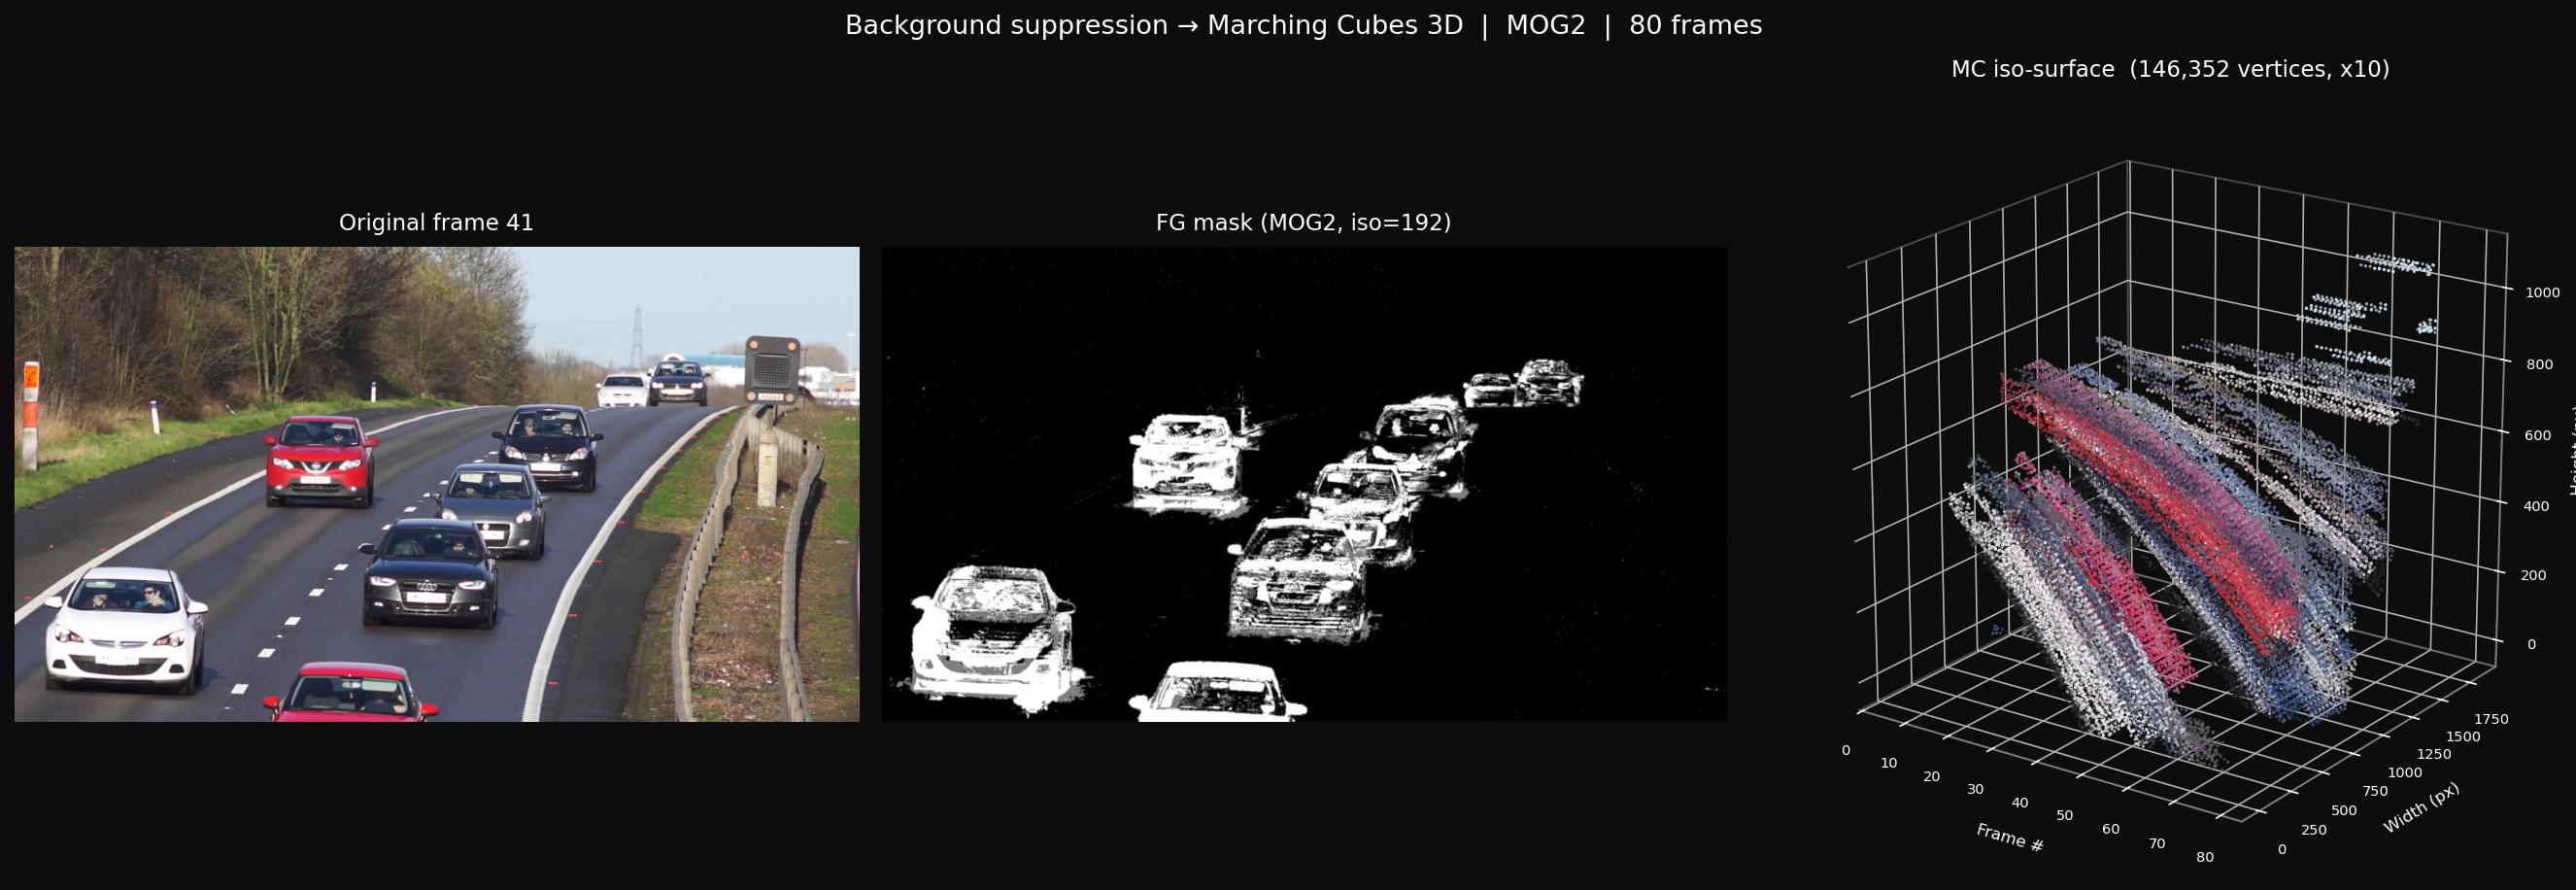

In [18]:
# ── Pick a representative mid-sequence frame ──────────────────────────────────
SNAP_FRAME = min(len(orig_frames) // 2, len(orig_frames) - 1)

orig_rgb = cv2.cvtColor(orig_frames[SNAP_FRAME], cv2.COLOR_BGR2RGB)
mask_rgb = cv2.cvtColor(mask_frames[SNAP_FRAME], cv2.COLOR_GRAY2RGB)

# ── Subsample vertices for the 3D scatter (every Nth point) ──────────────────
N_SCATTER = max(1, len(t_coord) // 40_000)   # target ~40k points
idx_s     = np.arange(0, len(t_coord), N_SCATTER)
intensity_s = t_coord[idx_s] / max(t_coord.max(), 1)
point_c = vert_rgb[idx_s] / 255.0 if COLOR_MODE == 'video' else intensity_s

# ── Build the combined 3-panel figure ────────────────────────────────────────
fig_comb = plt.figure(figsize=(18, 6), facecolor='#0d0d0d')

# Panel 1 — original frame
ax1 = fig_comb.add_subplot(1, 3, 1)
ax1.imshow(orig_rgb)
ax1.set_title(f'Original frame {SNAP_FRAME + 1}',
              color='white', fontsize=11, pad=8)
ax1.axis('off')

# Panel 2 — foreground mask
ax2 = fig_comb.add_subplot(1, 3, 2)
ax2.imshow(mask_rgb)
ax2.set_title(f'FG mask ({ALGO}, iso={ISO_LEVEL})',
              color='white', fontsize=11, pad=8)
ax2.axis('off')

# Panel 3 — Marching Cubes 3D scatter
ax3 = fig_comb.add_subplot(1, 3, 3, projection='3d')
ax3.set_facecolor('#0d0d0d')
sc = ax3.scatter(
    t_coord[idx_s], x_coord[idx_s], y_coord[idx_s],
    c=point_c,
    cmap=None if COLOR_MODE == 'video' else 'plasma',
    s=0.3, alpha=0.7,
)
ax3.set_xlabel('Frame #',    color='white', fontsize=8, labelpad=4)
ax3.set_ylabel('Width (px)', color='white', fontsize=8, labelpad=4)
ax3.set_zlabel('Height (px)',color='white', fontsize=8, labelpad=4)
ax3.tick_params(colors='white', labelsize=7)
ax3.xaxis.pane.fill = False
ax3.yaxis.pane.fill = False
ax3.zaxis.pane.fill = False
for spine in [ax3.xaxis, ax3.yaxis, ax3.zaxis]:
    spine.line.set_color('grey')
    spine.pane.set_edgecolor('grey')
ax3.view_init(elev=20, azim=-55)
ax3.set_box_aspect([1, 1, 1])
ax3.set_title(f'MC iso-surface  ({verts.shape[0]:,} vertices, x{DOWNSCALE_USED})',
              color='white', fontsize=11, pad=8)
if COLOR_MODE != 'video':   # a colourbar only makes sense for the frame colourscale
    cbar = fig_comb.colorbar(sc, ax=ax3, shrink=0.5, pad=0.12)
    cbar.set_label('Frame # (normalised)', color='white', fontsize=8)
    cbar.ax.yaxis.set_tick_params(color='white', labelsize=7)
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')

plt.suptitle(
    f'Background suppression → Marching Cubes 3D  |  {ALGO}  |  {len(mask_frames)} frames',
    color='white', fontsize=13, y=1.01
)
plt.tight_layout()

COMBINED_PNG = os.path.join(IMAGES_DIR, 'background_combined.png')
plt.savefig(COMBINED_PNG, dpi=150, bbox_inches='tight',
            facecolor=fig_comb.get_facecolor())
plt.close()
print(f'Combined PNG saved: {COMBINED_PNG}')

# ── Display inline (thumbnail only — does not embed the full Plotly HTML) ─────
from IPython.display import Image, display
display(Image(COMBINED_PNG, width=900))